In [105]:
import numpy as np
import re 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import os
import pandas as pd
import json

In [139]:
class read_ising_file:

    def __init__(self, file):
        
        self.file = file
        # Leer archivo
        with open(file, 'r') as f:
            self.metadata = json.loads(f.readlines()[0][:-1])  

    def reshape_spin(self, index):
        """ Convertir un vector de espines plano a una matriz de espines tamaño LxL"""

        # Leer linea
        with open(self.file, 'r') as f:
            spin =  f.readlines()[index][:-1] 
        
        # Convertir a np.array
        arr = np.fromstring(spin, dtype=int, sep=',')
        arr = arr.reshape(self.metadata['L'], self.metadata['L'])
        return arr

    def plot_spin(self, spin_index=1, spin_arrows=True):
        """Graficar red de espines en B/N, con opción de flechas ↑ ↓ en cada celda"""
        spin = self.reshape_spin(spin_index)
        L = self.metadata["L"]

        plt.figure(figsize=(6, 6))
        plt.imshow(spin, cmap='gray', vmin=-1, vmax=1)

        plt.title(f'Red de espines T = {self.metadata["T"]}')
        plt.xlabel(f'Tamaño de la red: {L} x {L}')
        plt.ylabel('')

        if spin_arrows:
            # Dibuself.self.self.self.metadata['J']ar flechas con color según espín
            for i in range(L):
                for self.metadata['J'] in range(L):
                    arrow = '↑' if spin[i, self.metadata['J']] == 1 else '↓'
                    color = 'black' if spin[i, self.metadata['J']] == 1 else 'white'
                    plt.text(
                        self.metadata['J'], i, arrow,
                        ha='center', va='center',
                        color=color, fontsize=14, fontweight='bold'
                    )

        plt.xticks([])
        plt.yticks([])
        plt.show()

    def magnetization(self, index):
        """Calcular magnetización de la red de espines"""
        spin = self.reshape_spin(index)
        return np.sum(spin)

    def energy(self, index):
        """Calcular energía de la red de espines, con interacción entre primeros vecinos y campo magnético externo"""

        spin = self.reshape_spin(index)

        # Término de interacción entre primeros vecinos
        interaction_energy = 0.0
        
        # Interacciones horizontales (hacia la derecha)
        interaction_energy -= self.metadata['J'] * np.sum(spin[:, :-1] * spin[:, 1:])
        interaction_energy -= self.metadata['J'] * np.sum(spin[:, -1] * spin[:, 0])  # Condición periódica
        
        # Interacciones verticales (hacia abaself.metadata['J']o)
        interaction_energy -= self.metadata['J'] * np.sum(spin[:-1, :] * spin[1:, :])
        interaction_energy -= self.metadata['J'] * np.sum(spin[-1, :] * spin[0, :])  # Condición periódica
        
        # Término del campo magnético externo
        field_energy = -self.metadata['H'] * np.sum(spin)
        
        return interaction_energy + field_energy


In [161]:
# Filtrar temperaturas desde objective_files y seleccionar archivos objetivo
temps = []
folder = './../data/'

T = ['0.700', '1.000', '1.700', '2.000', '2.300', '3.000', '3.500', '4.000'] # Temperaturas objetivo
patron = re.compile(r"_T([0-9.]+)_")  # Patrón para extraer temperaturas desde el filename

objective_files = []
for file in os.listdir(folder):
    match = patron.search(file)

    if match:
        # Extraer temperatura desde el filename
        temp_match = f"{float(match.group(1)):.3f}"
        temps.append(temp_match)

        # Agregar objective_files para temperaturas objetivo
        if temp_match in T and file not in objective_files:
            objective_files.append(file) 


In [162]:
energy_distribution = read_ising_file('./../data/' + objective_files[0])

energy = []
for i in range(1, energy_distribution.metadata['N']):
    energy.append(energy_distribution.energy(i))



# Energía

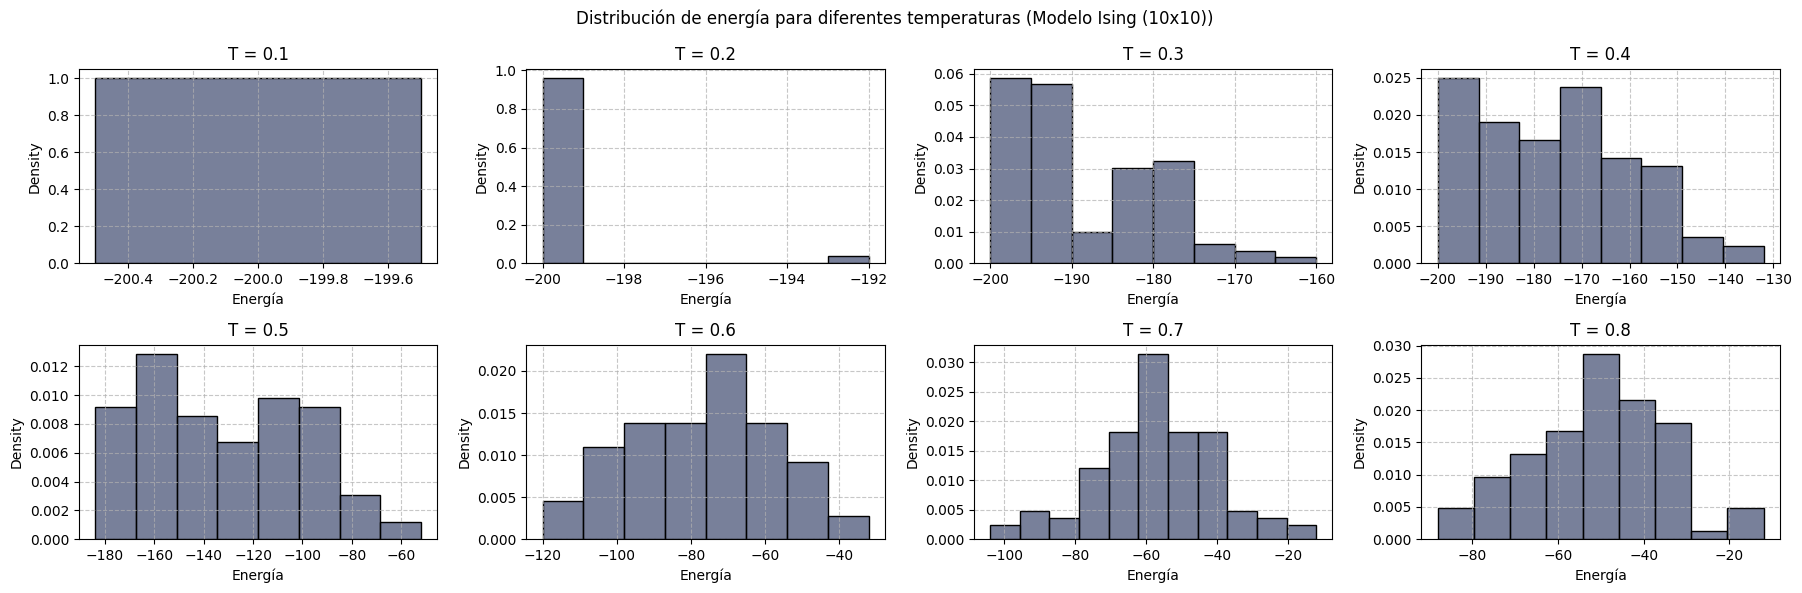

In [173]:

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])

    # Read file and calculate energy distribution
    file = objective_files[i]
    ising = read_ising_file('./../data/' + file) 
    energy = [ising.energy(i) for i in range(1, ising.metadata['N'])]

    sns.histplot(energy, ax=ax, color="#3f4b6f", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Energía')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de energía para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.show()


# Magenización

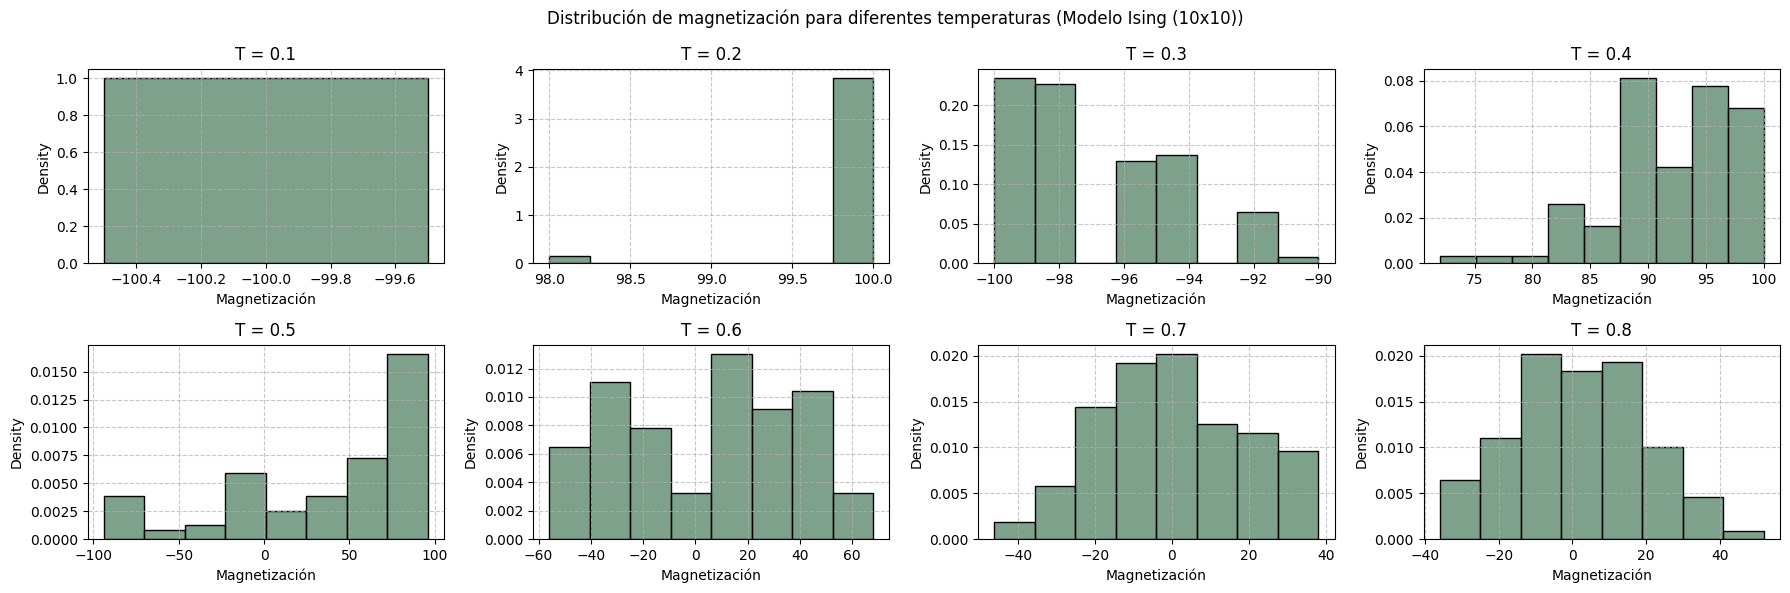

In [174]:

# Crear la figura y la grilla 
fig = plt.figure(figsize=(18, 6))
gs = gridspec.GridSpec(2, 4)

for i in range(8):
    ax = fig.add_subplot(gs[i])
    
    file = objective_files[i]
    ising = read_ising_file('./../data/' + file) 
    magnetization= [ising.magnetization(i) for i in range(1, ising.metadata['N'])]

    sns.histplot(magnetization, ax=ax, color="#47795a", alpha=0.7, stat="density")
    ax.set_title(f"T = {T[i]}")
    ax.set_xlabel('Magnetización')
    ax.grid(True, linestyle="--", alpha=0.7)

fig.suptitle("Distribución de magnetización para diferentes temperaturas (Modelo Ising (10x10))")

plt.tight_layout()
plt.show()


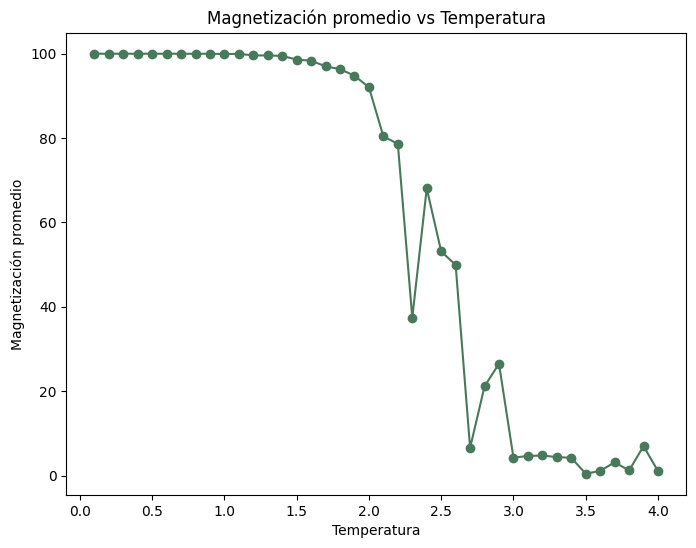

In [179]:
T = np.array(temps, dtype=float)
folder = './../data/'
M_mean = []

for file in os.listdir(folder):
    ising = read_ising_file(folder + file)
    M_mean.append(np.mean([ising.magnetization(i) for i in range(1, ising.metadata['N'])]))


M_mean = np.abs(np.array(M_mean))

plt.figure(figsize=(8, 6))
plt.plot(T, M_mean, marker='o', linestyle='-', color='#47795a')

plt.xlabel('Temperatura')
plt.ylabel('Magnetización promedio')
plt.title('Magnetización promedio vs Temperatura')
plt.show()
